In [3]:
import numpy as np
import pandas as pd 

import matplotlib.pyplot as plt 
%matplotlib inline
import seaborn as sns

import warnings  # suppress warnings 
warnings.filterwarnings('ignore')

from itertools import cycle
cycol = cycle('gbmrc')  # for colors

In [4]:
# read csv
c1 = pd.read_csv("World_Development_Indicators_2\world_bank_data.csv")
c2 = pd.read_csv("World_Development_Indicators_3\world_bank_data.csv")
countries = c1.merge(c2, how="outer", sort=False) 

# data cleaning
countries_dict = {}
def get_country_data(country_name: str):
    result = countries[countries["Country Name"] == country_name].drop(columns = ["Country Name", "Country Code", "Series Code"])
    if result.size > 0: 
        result = result.transpose()      # flip the table 
        result.columns = result.iloc[0]  # set columns to data variables 
        result = result[1:]
        result.index = pd.to_numeric(result.index.str[:4])  # alter the index (years) to yyyy format
        for col in result.columns:
            result[col] = pd.to_numeric(result[col], errors='coerce')   # convert everything from dtype 'object' to numeric 
        countries_dict[country_name] = result
        return result
    else:
        print("Invalid argument: ", country_name)
        return -1

# get data 
world = get_country_data("World")
united_states = get_country_data("United States")
japan = get_country_data("Japan")
china = get_country_data("China")
india = get_country_data("India")
low_income = get_country_data("Low income")
middle_income = get_country_data("Middle income")
high_income = get_country_data("High income")


In [14]:
# this cell as been deactivated, use esc + y to reactivate

# list varibles in data (columns)  note: the columns and index should be the same for all country dataframes 
print("COLUMNS:")
for col in world.columns:
    print(col)

# list years in data (index)
print("\nINDEX:")
print(world.index[1], "-", world.index[-1])
# for i in world.index:
#     print(i)

COLUMNS:
Population, total
Population growth (annual %)
Surface area (sq. km)
Population density (people per sq. km of land area)
Poverty headcount ratio at national poverty lines (% of population)
Poverty headcount ratio at $2.15 a day (2017 PPP) (% of population)
GNI, Atlas method (current US$)
GNI per capita, Atlas method (current US$)
GNI, PPP (current international $)
GNI per capita, PPP (current international $)
Income share held by lowest 20%
Life expectancy at birth, total (years)
Fertility rate, total (births per woman)
Adolescent fertility rate (births per 1,000 women ages 15-19)
Contraceptive prevalence, any method (% of married women ages 15-49)
Mortality rate, under-5 (per 1,000 live births)
Prevalence of underweight, weight for age (% of children under 5)
Primary completion rate, total (% of relevant age group)
School enrollment, primary (% gross)
School enrollment, secondary (% gross)
School enrollment, primary and secondary (gross), gender parity index (GPI)
Forest area

In [5]:
def standardize(data):
    mean = data.mean()
    std = data.std()
    
    if std == 0:
        raise ValueError("Standard deviation is zero. Data cannot be standardized.")  # prevent divide by 0 error 
    
    return (data - mean) / std

In [26]:
# creates a plot for all avalible countries 
# fplot (function) - the function used to plot (eg. plot_population_ages)
def plot_all(fplot, title: str = "Data"):
    plt.figure(figsize=(10, 18))
    count = 1
    for country_name in countries_dict:
        plt.subplot(4, 2, count)
        count += 1
        sns.set_style("whitegrid") 
        fplot(countries_dict[country_name][:])    # change this part to show a different relationship 
        plt.title(country_name)
        
    
    plt.suptitle(title+"\n")
    plt.tight_layout()  
    plt.show()

In [44]:
# create population demography plots
def plot_population_ages(data):
    data = data[["Population ages 0-14, total", "Population ages 15-64, total", "Population ages 65 and above, total"]] / 1000000 # population in millions
    sns.lineplot(data)
    plt.ylim(0, data.max().max()+20)
    plt.xlabel("Year") 
    plt.ylabel("Population (millions)") 
    plt.legend(title="Demographic Groups", loc="upper left", prop={'size': 8})
    # sns.set_style("white") 

def plot_population_growth(data):
    sns.lineplot(data["Population growth (annual %)"], color=next(cycol))
    #plt.ylim(-1, 3.2)
    plt.xlabel("Year") 

In [8]:
def plot_population_labor(data, title: str):
    plt.figure(figsize=(10, 3))
    color="b"
    color2="r"
    
    plt.subplot(1, 3, 1)
    sns.lineplot(data["Population growth (annual %)"], color = color)
    plt.xlim(1960, 2023)
    plt.xlabel("Year") 
    plt.ylabel("Population growth") 
    plt.title("% Population growth over time") 

    plt.subplot(1, 3, 2)
    sns.lineplot(data["Labor force participation rate, total (% of total population ages 15+) (national estimate)"], color = color2)
    plt.xlim(1960, 2023)
    plt.xlabel("Year") 
    plt.ylabel("Labor force participation rate") 
    plt.title(" % Labor force participation rate over time")
    
    plt.subplot(1, 3, 3)
    # sns.regplot(x= standardize(data["Labor force participation rate, total (% of total population ages 15+) (national estimate)"]), y=standardize(data["Population growth (annual %)"]), color = color)
    sns.lineplot(standardize(data["Labor force participation rate, total (% of total population ages 15+) (national estimate)"]), label = "Labor force", color = color2)
    sns.lineplot(standardize(data["Population growth (annual %)"]), label = "Population growth",color = color)
    plt.legend(loc="upper right", prop={'size': 7})
    plt.xlabel("Year") 
    plt.ylabel("Z-score") 
    plt.title("Correlation") 

    plt.suptitle(title)
    plt.tight_layout()  
    plt.show()

In [9]:
# functions for relationships with dependency ratio vs economic factors

def get_dependency_ratio(data):
    data["Num dependents"] = data["Population ages 0-14, total"] + data["Population ages 65 and above, total"]
    data["Dependency ratio"] = data["Num dependents"] / data["Population ages 15-64, total"]
    return data

def plot_dependency_ratio(data):
    data = get_dependency_ratio(data)
    sns.lineplot(data["Dependency ratio"], color=next(cycol))
    # plt.ylim(0.3,1)

def plot_dependency_exports(data):
    data = get_dependency_ratio(data)
    data["Exports of goods and services"] = data["GDP (current US$)"] * (data["Exports of goods and services (% of GDP)"] / 100)
    sns.regplot(x=data["Dependency ratio"], y=data["Exports of goods and services"], color=next(cycol))

def plot_dependency_exports_percentage(data):
    data = get_dependency_ratio(data)
    sns.regplot(x=data["Dependency ratio"], y=data["Exports of goods and services (% of GDP)"], color=next(cycol))

def plot_dependency_net_exports(data):
    data = get_dependency_ratio(data)
    data["Exports of goods and services"] = data["GDP (current US$)"] * (data["Exports of goods and services (% of GDP)"] / 100)
    data["Imports of goods and services"] = data["GDP (current US$)"] * (data["Imports of goods and services (% of GDP)"] / 100)
    data["Net exports of goods and services"] = data["Exports of goods and services"] - data["Imports of goods and services"]    
    sns.regplot(x=data["Dependency ratio"], y=data["Net exports of goods and services"], color=next(cycol))

def plot_dependency_imports(data):
    data = get_dependency_ratio(data)
    data["Imports of goods and services"] = data["GDP (current US$)"] * (data["Imports of goods and services (% of GDP)"] / 100)
    sns.regplot(x=data["Dependency ratio"], y=data["Imports of goods and services"], color=next(cycol))

def plot_dependency_imports_percentage(data):
    data = get_dependency_ratio(data)
    sns.regplot(x=data["Dependency ratio"], y=data["Imports of goods and services (% of GDP)"], color=next(cycol))

def plot_dependency_net_imports(data):
    data = get_dependency_ratio(data)
    data["Exports of goods and services"] = data["GDP (current US$)"] * (data["Exports of goods and services (% of GDP)"] / 100)
    data["Imports of goods and services"] = data["GDP (current US$)"] * (data["Imports of goods and services (% of GDP)"] / 100)
    data["Net imports of goods and services"] = data["Imports of goods and services"] - data["Exports of goods and services"]    
    sns.regplot(x=data["Dependency ratio"], y=data["Net imports of goods and services"], color=next(cycol))
    
def plot_dependency_gdp(data):
    data = get_dependency_ratio(data)
    sns.lineplot( standardize(data["GDP (current US$)"]), label = "GDP (current US$)", color="r")
    sns.lineplot( -standardize(data["Dependency ratio"]), label = "Dependency ratio (inverted)", color="b")

def plot_dependency_savings(data):
    data = get_dependency_ratio(data)
    sns.regplot(x=data["Dependency ratio"], y=data["Gross domestic savings (% of GDP)"], color=next(cycol))

def plot_dependency_consumption(data):
    data = get_dependency_ratio(data)
    sns.regplot(x=data["Dependency ratio"], y=data["Final consumption expenditure (% of GDP)"], color=next(cycol))

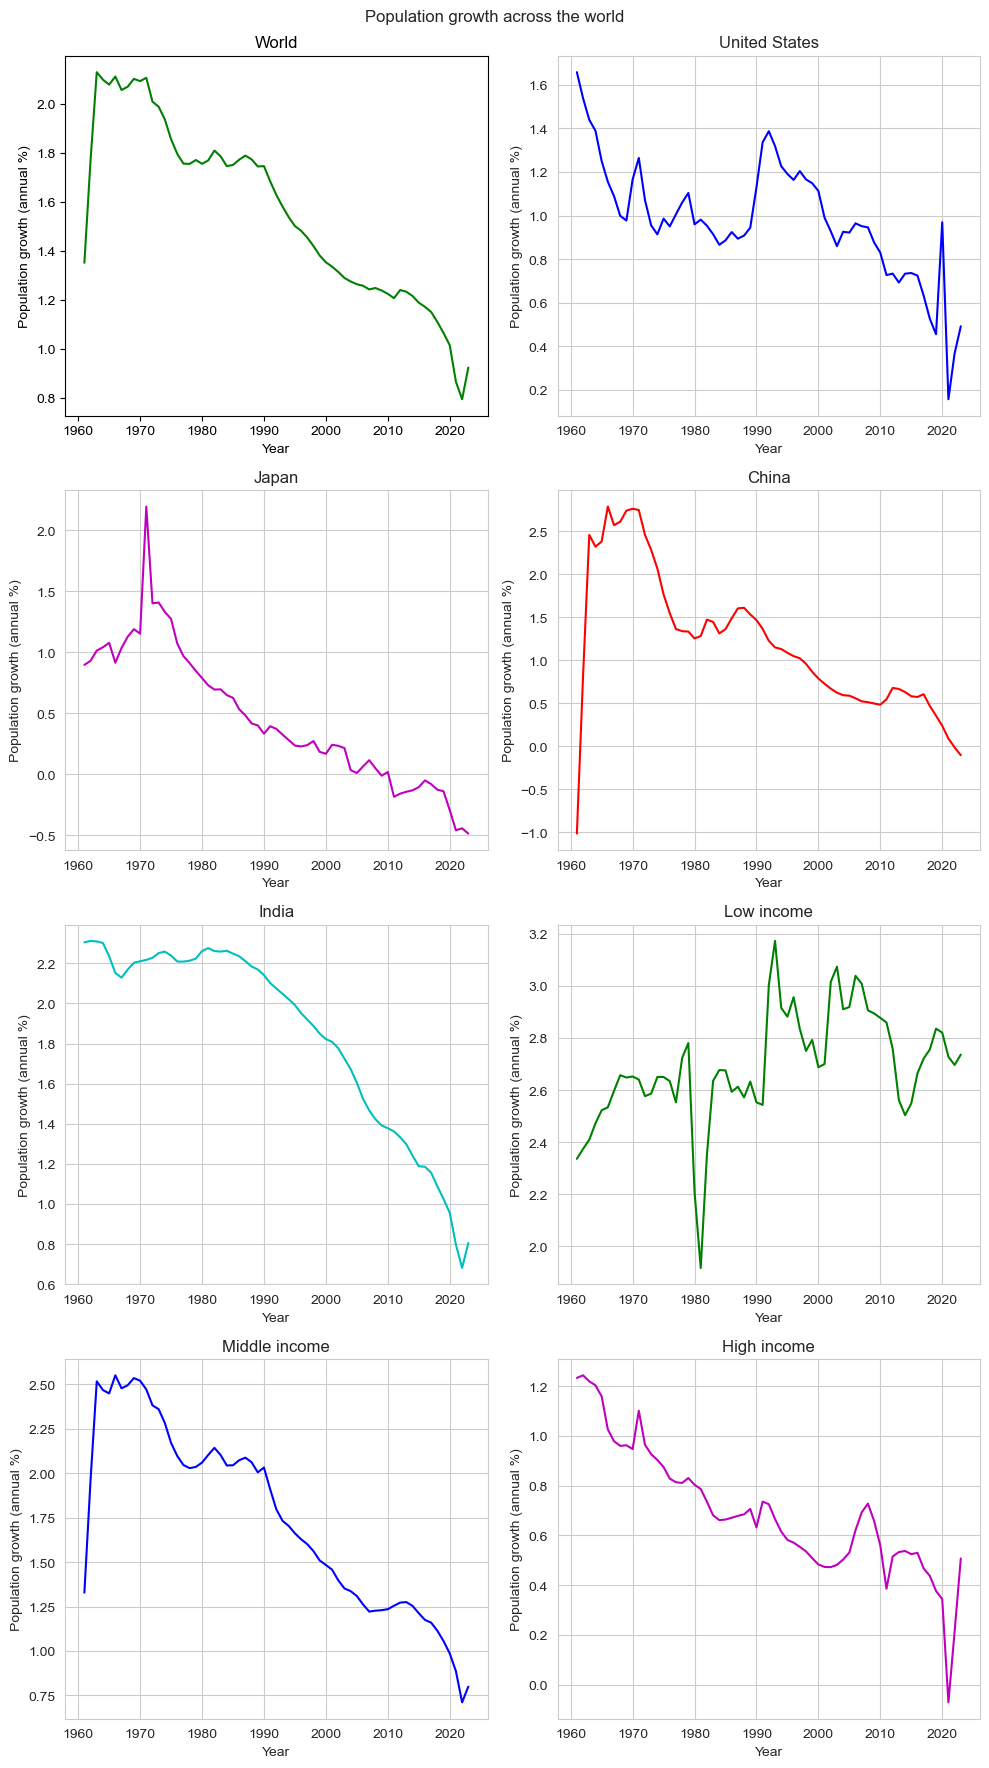

In [12]:
plot_all(plot_population_growth, "Population growth across the world")

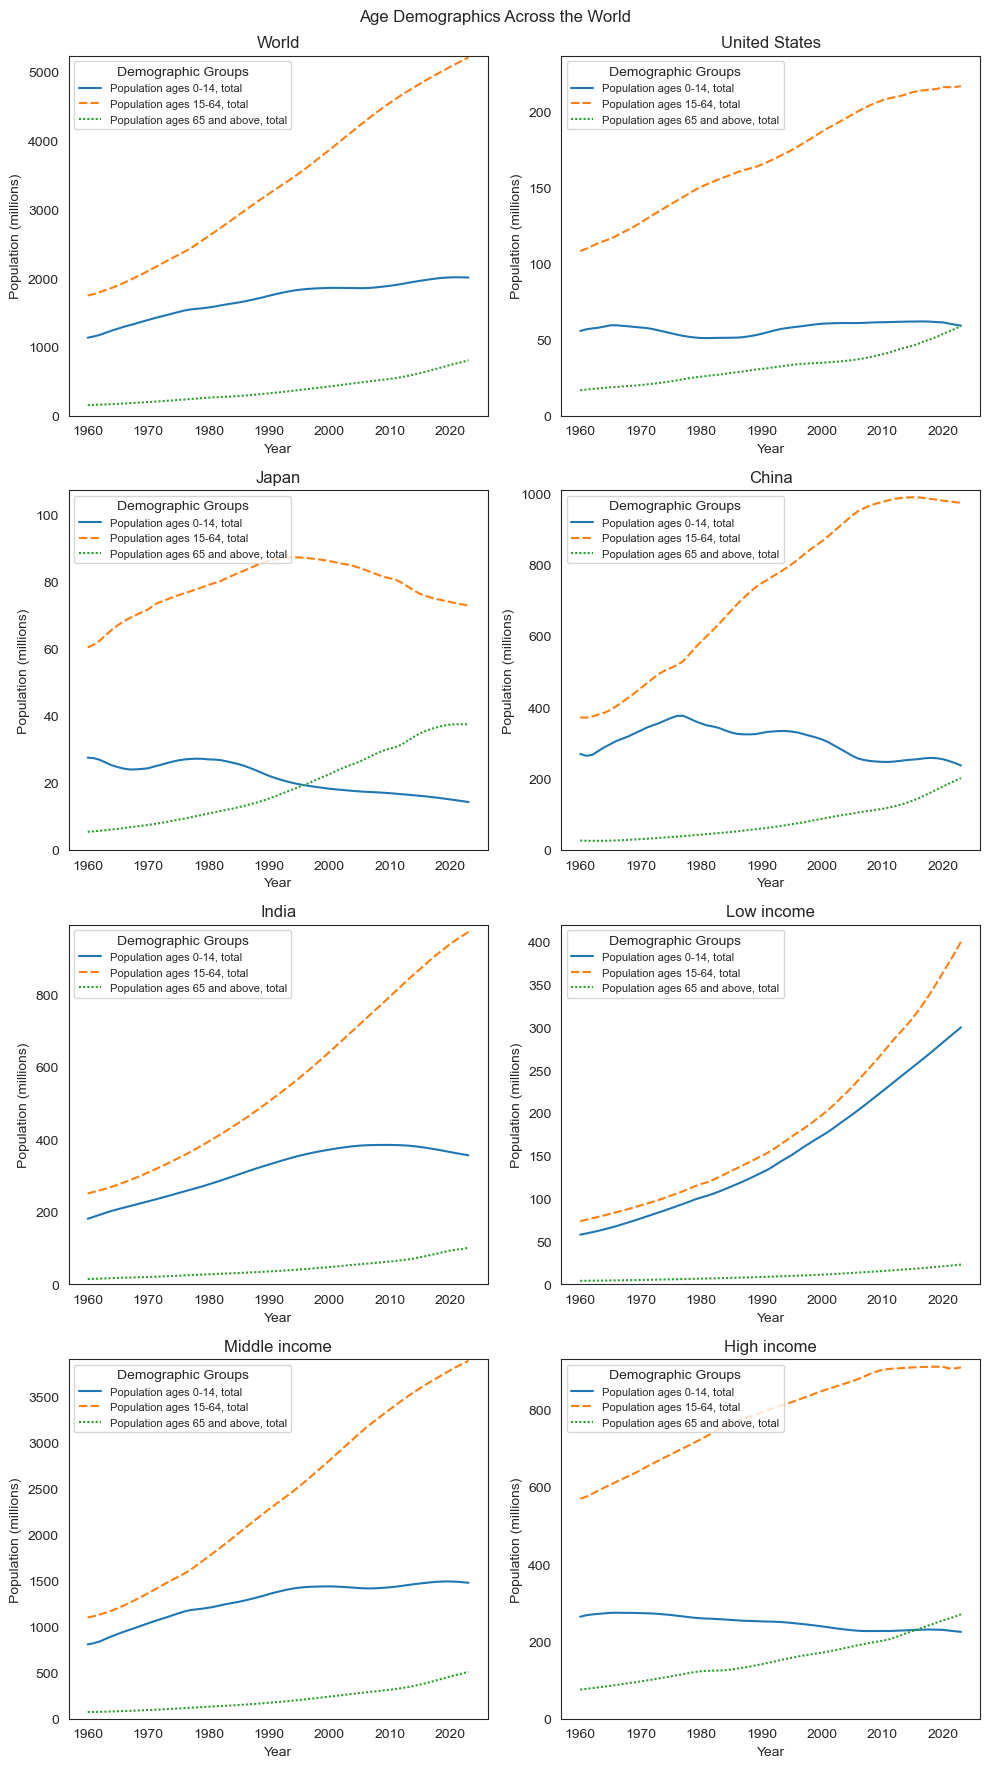

In [301]:
plot_all(plot_population_ages, "Age Demographics Across the World")

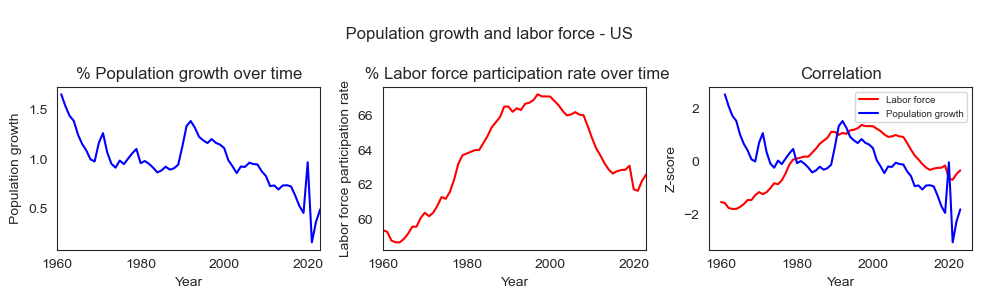

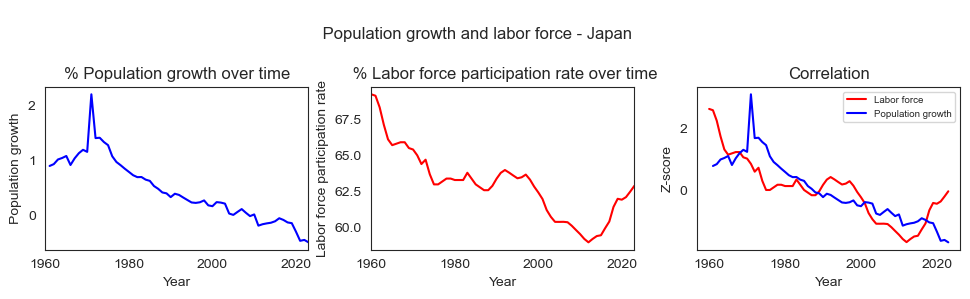

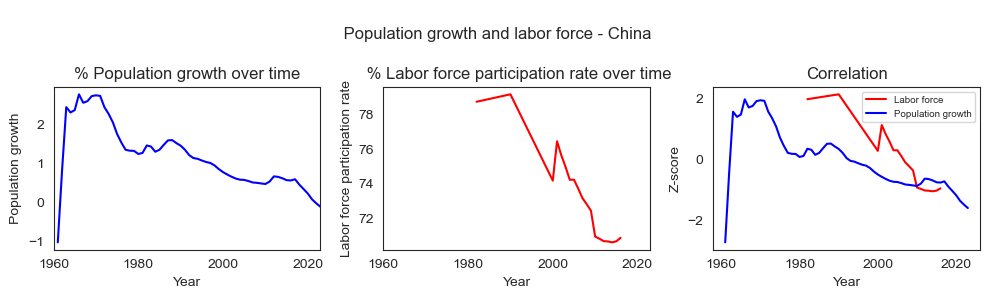

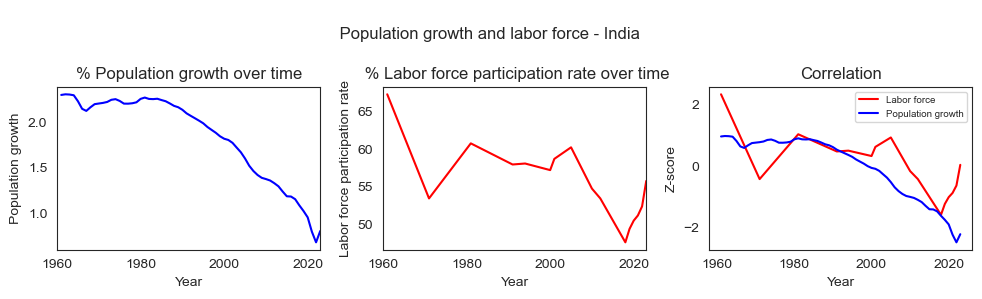

In [303]:
# plot population  
plot_population_labor(united_states[:], "\n Population growth and labor force - US")
plot_population_labor(japan[:], "\n Population growth and labor force - Japan")
plot_population_labor(china[:], "\n Population growth and labor force - China")
plot_population_labor(india[:], "\n Population growth and labor force - India")

In [203]:
from IPython.display import Markdown
Markdown("""## Dependency ratio = # dependents / # working-age population 
\n### A large dependency ratio puts strain on the working-age population who has to economically support those who are too young / old to work""")

## Dependency ratio = # dependents / # working-age population 

### A large dependency ratio puts strain on the working-age population who has to economically support those who are too young / old to work

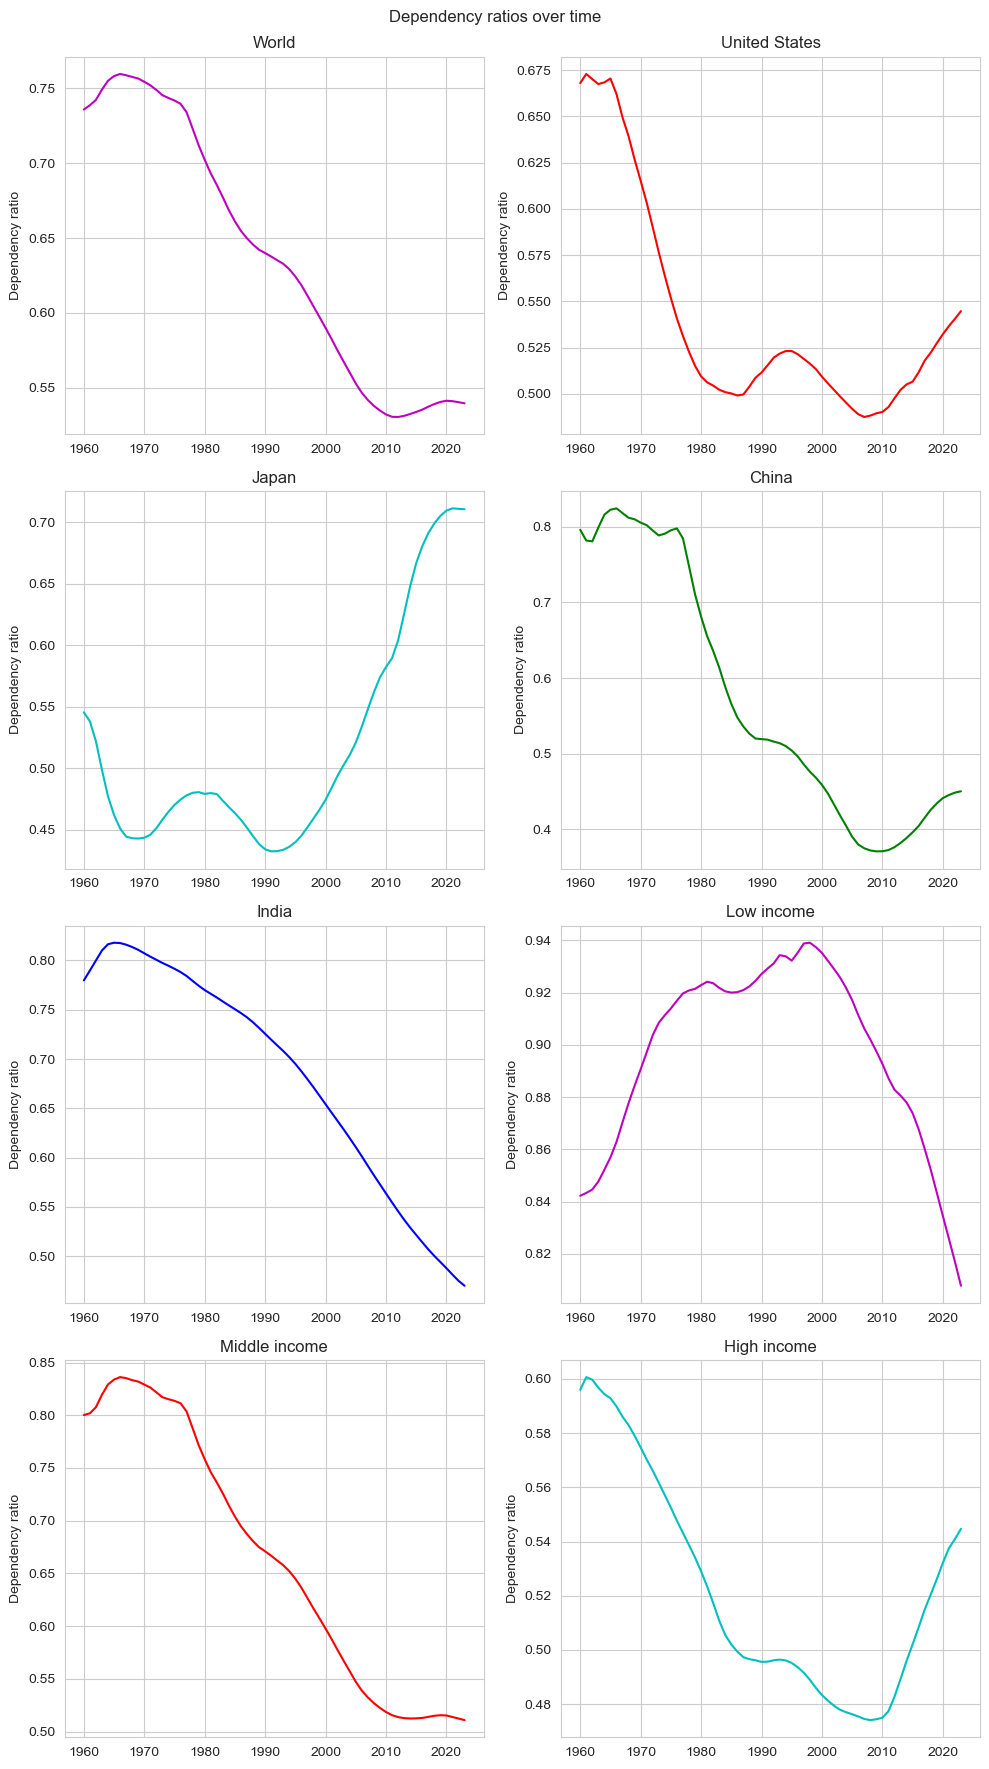

NOTE: y-lim is not standardized, the purpose of these plots are to show dependency ratio trends, NOT to compare countries


In [307]:
plot_all(plot_dependency_ratio, "Dependency ratios over time")
print("NOTE: y-lim is not standardized, the purpose of these plots are to show dependency ratio trends, NOT to compare countries")

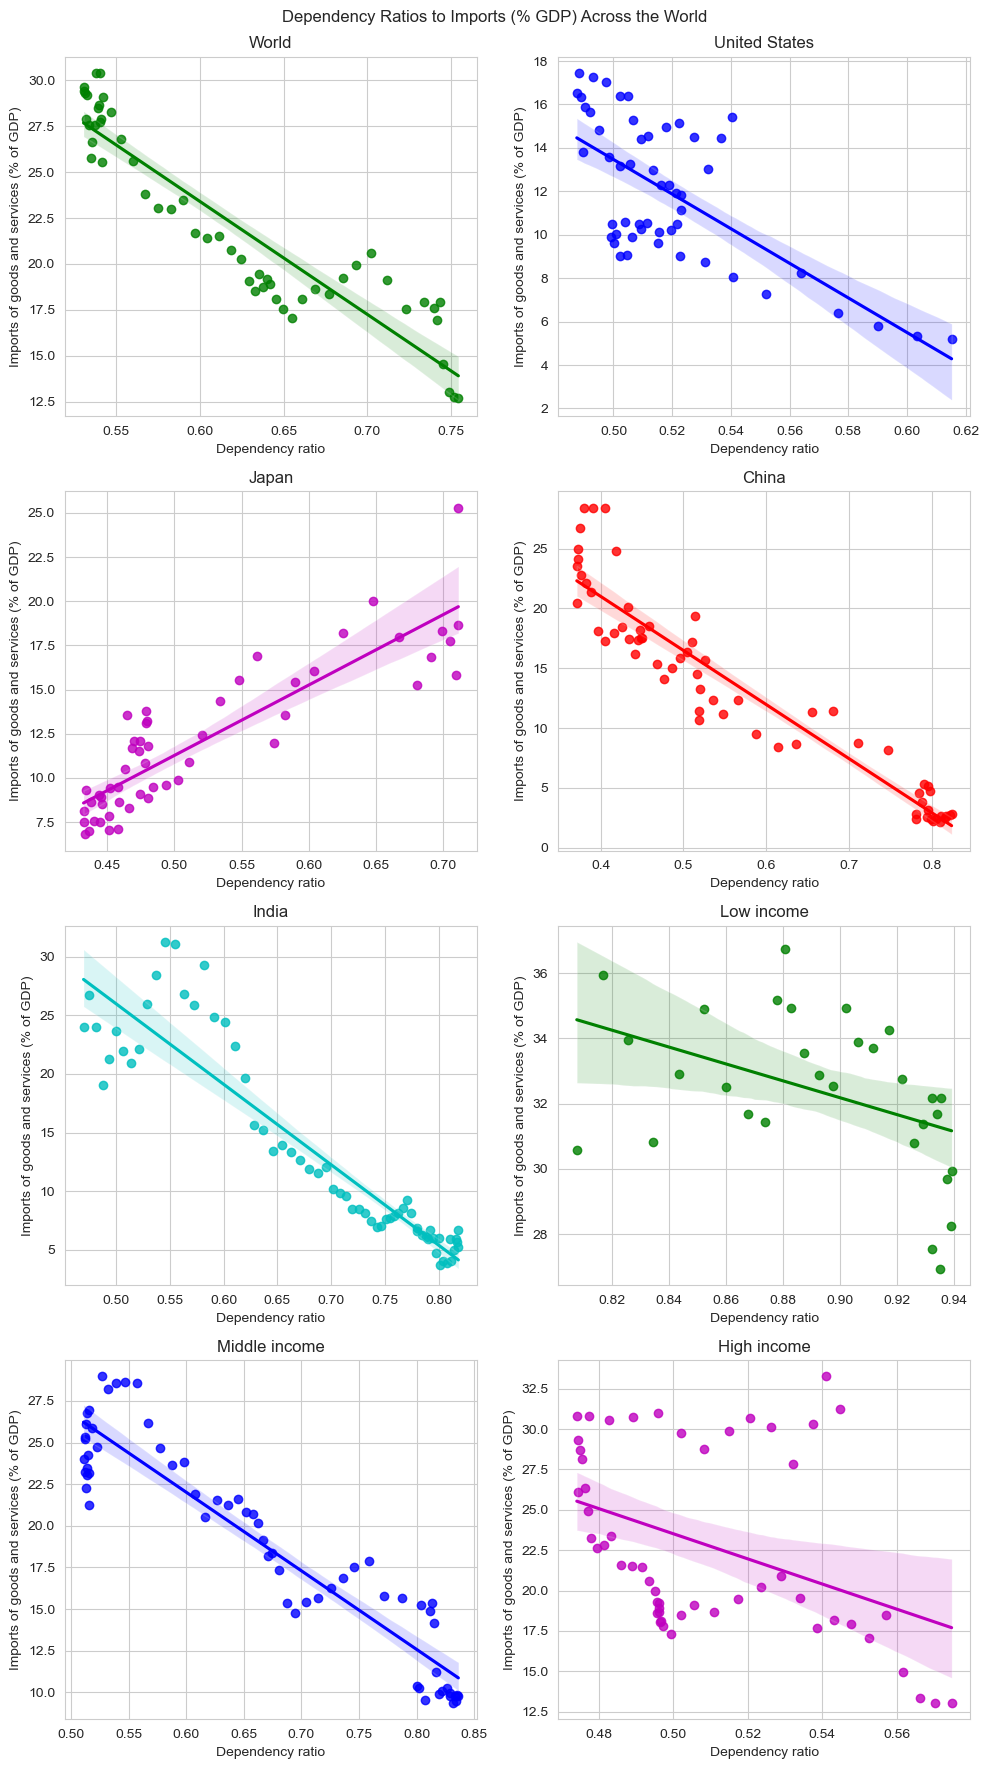

In [308]:
plot_all(plot_dependency_imports_percentage, "Dependency Ratios to Imports (% GDP) Across the World")

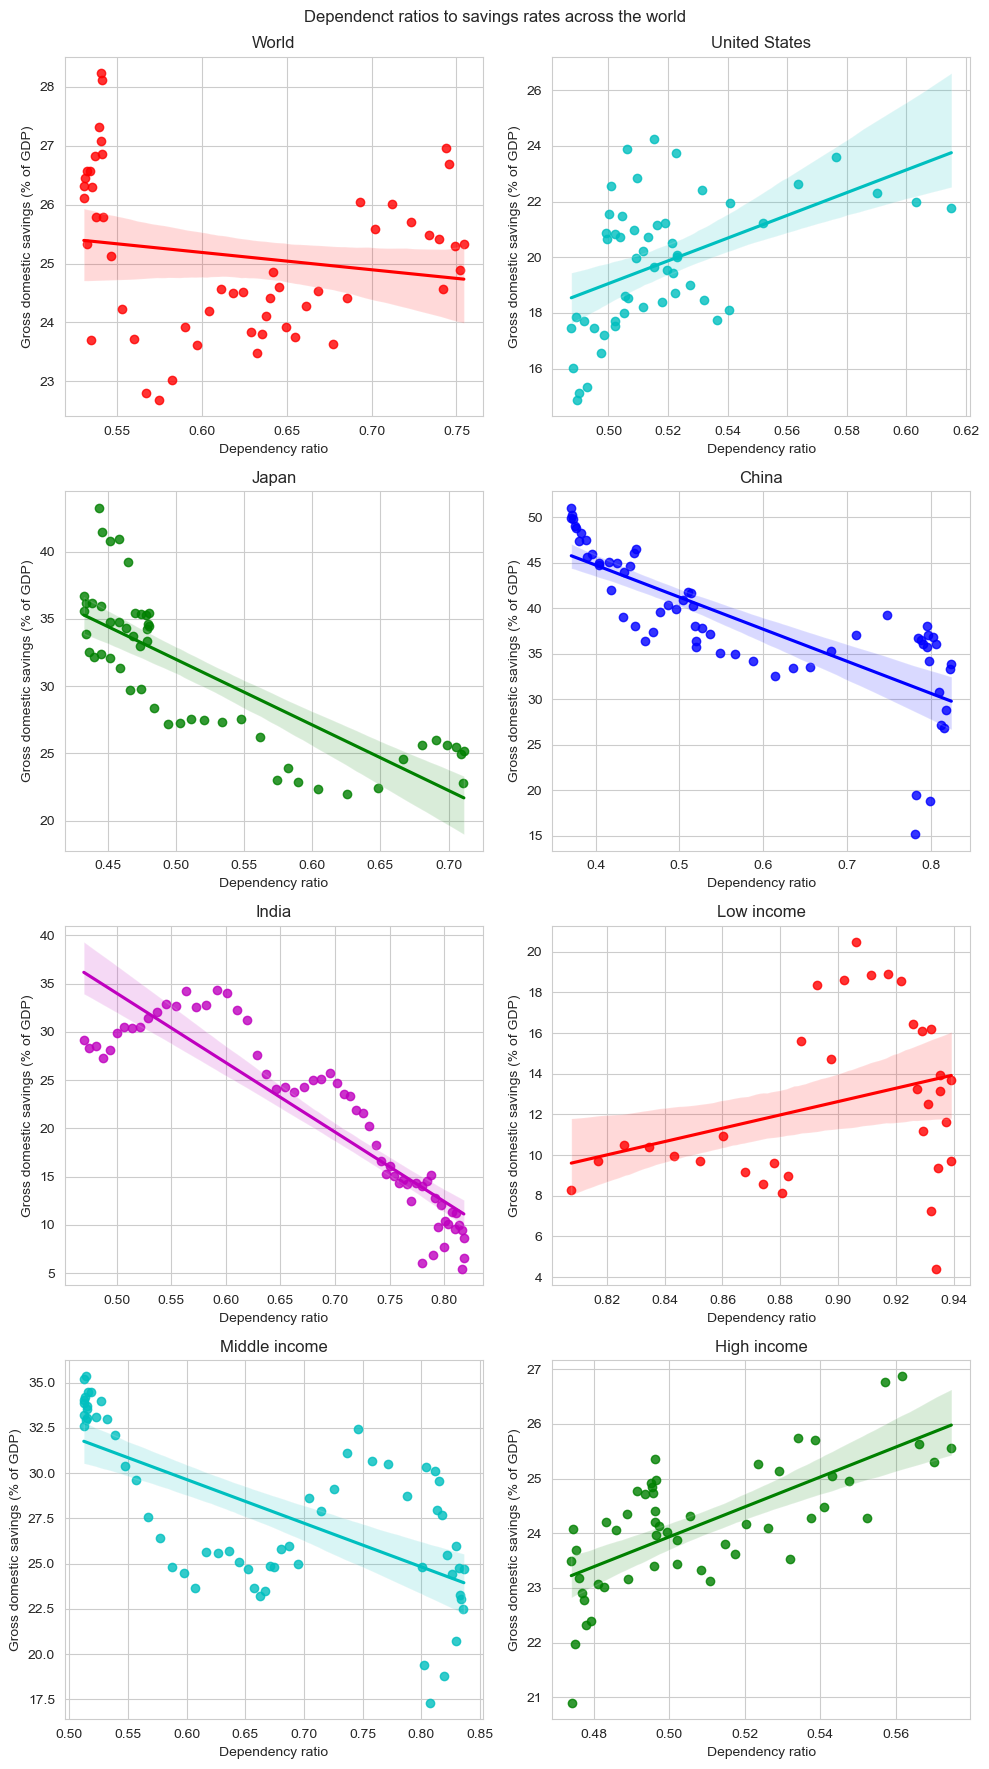

In [309]:
plot_all(plot_dependency_savings, "Dependenct ratios to savings rates across the world")

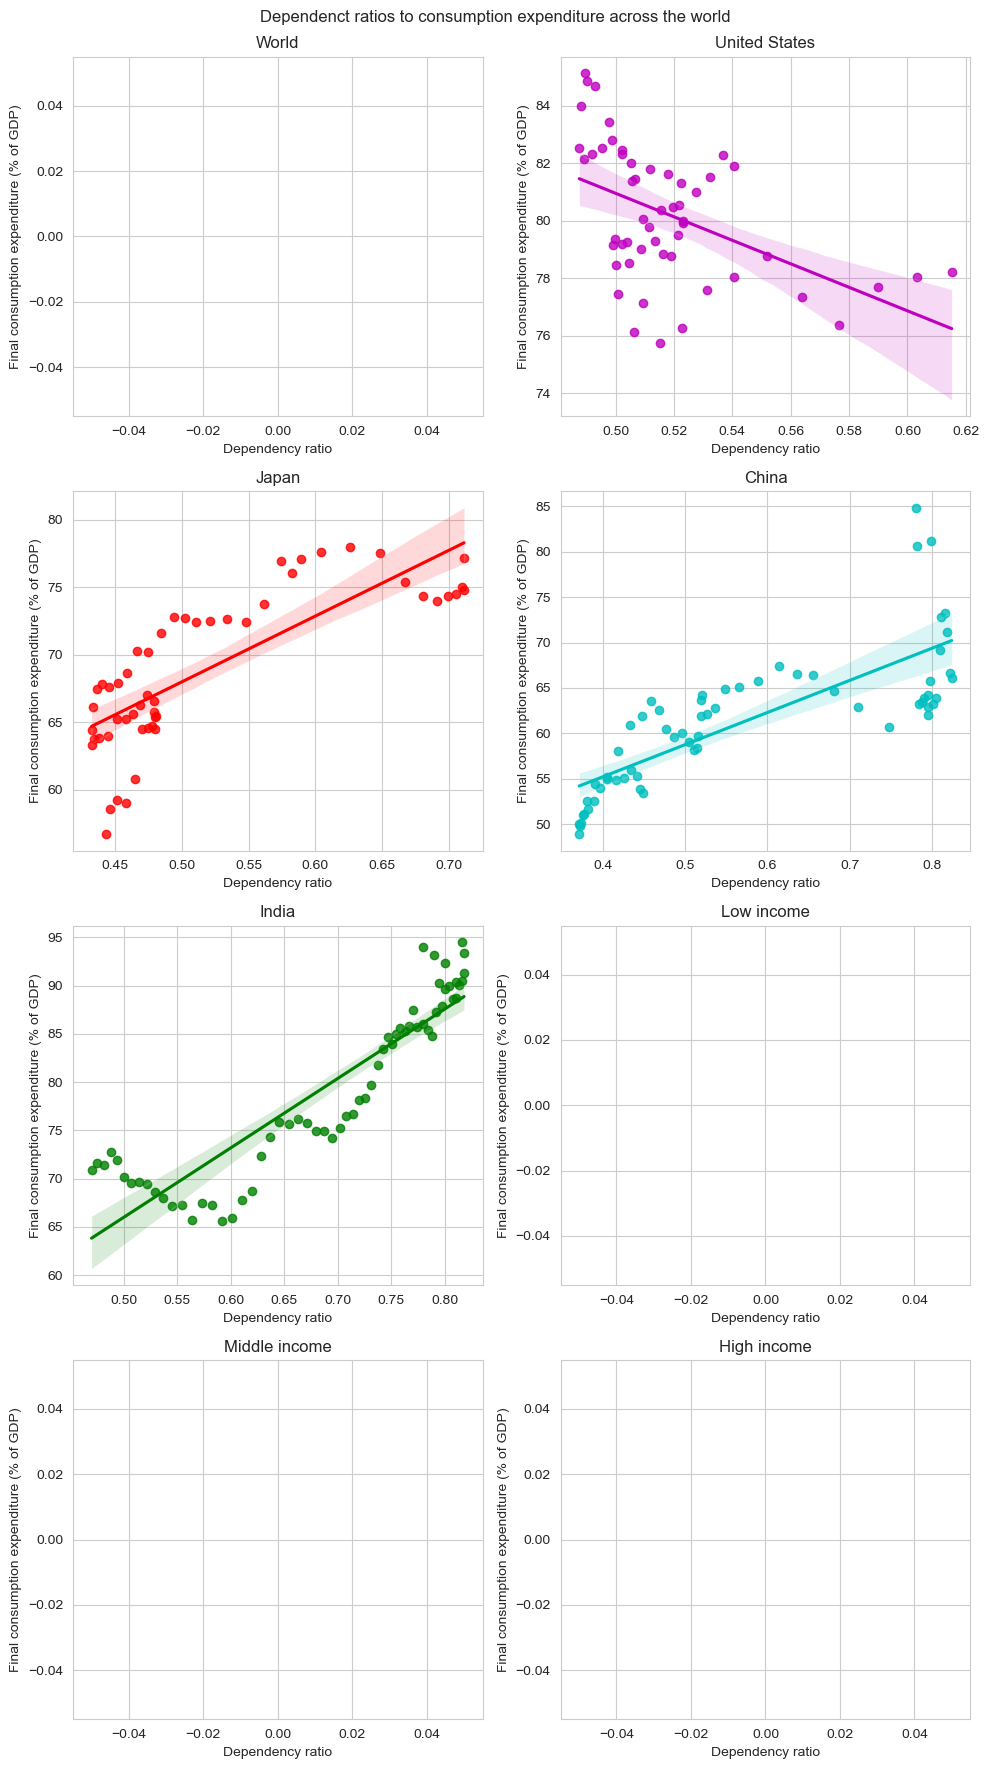

In [310]:
plot_all(plot_dependency_consumption, "Dependenct ratios to consumption expenditure across the world")

In [28]:
def plot_birth_rates(data):
    sns.lineplot(data["Fertility rate, total (births per woman)"], color=next(cycol))
    #plt.ylim(-1, 3.2)
    plt.xlabel("Year") 

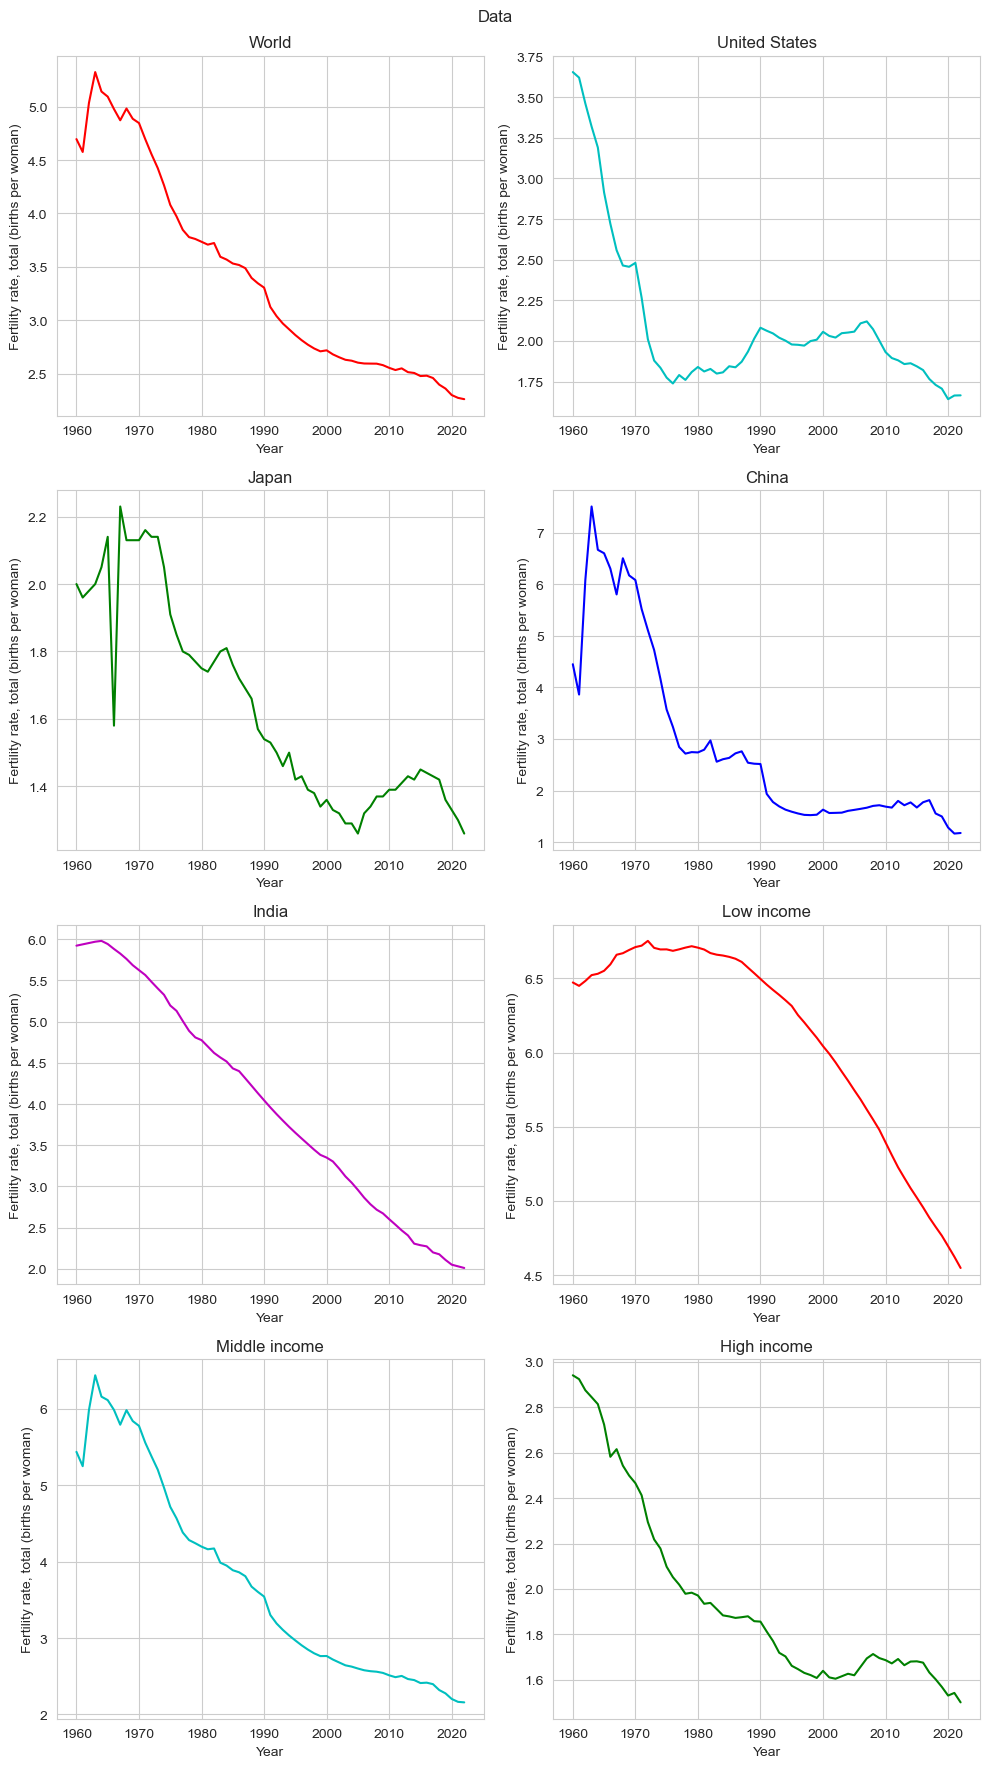

In [30]:
plot_all(plot_birth_rates)

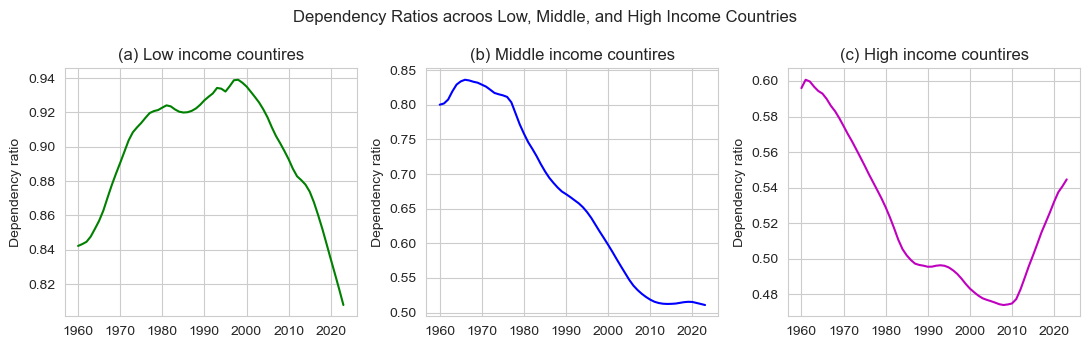

	NOTE: y-lim is not standardized, the purpose of these plots are to show dependency ratio trends, NOT to compare countries


In [66]:
plt.figure(figsize=(11, 3.5))
sns.set_style("whitegrid") 

plt.subplot(1, 3, 1)
plot_dependency_ratio(low_income[:]) 
plt.title("(a) Low income countires")

plt.subplot(1, 3, 2)
plot_dependency_ratio(middle_income[:]) 
plt.title("(b) Middle income countires")

plt.subplot(1, 3, 3)
plot_dependency_ratio(high_income[:]) 
plt.title("(c) High income countires")

plt.suptitle("Dependency Ratios acroos Low, Middle, and High Income Countries")
plt.tight_layout()  
plt.show()

print("\tNOTE: y-lim is not standardized, the purpose of these plots are to show dependency ratio trends, NOT to compare countries")

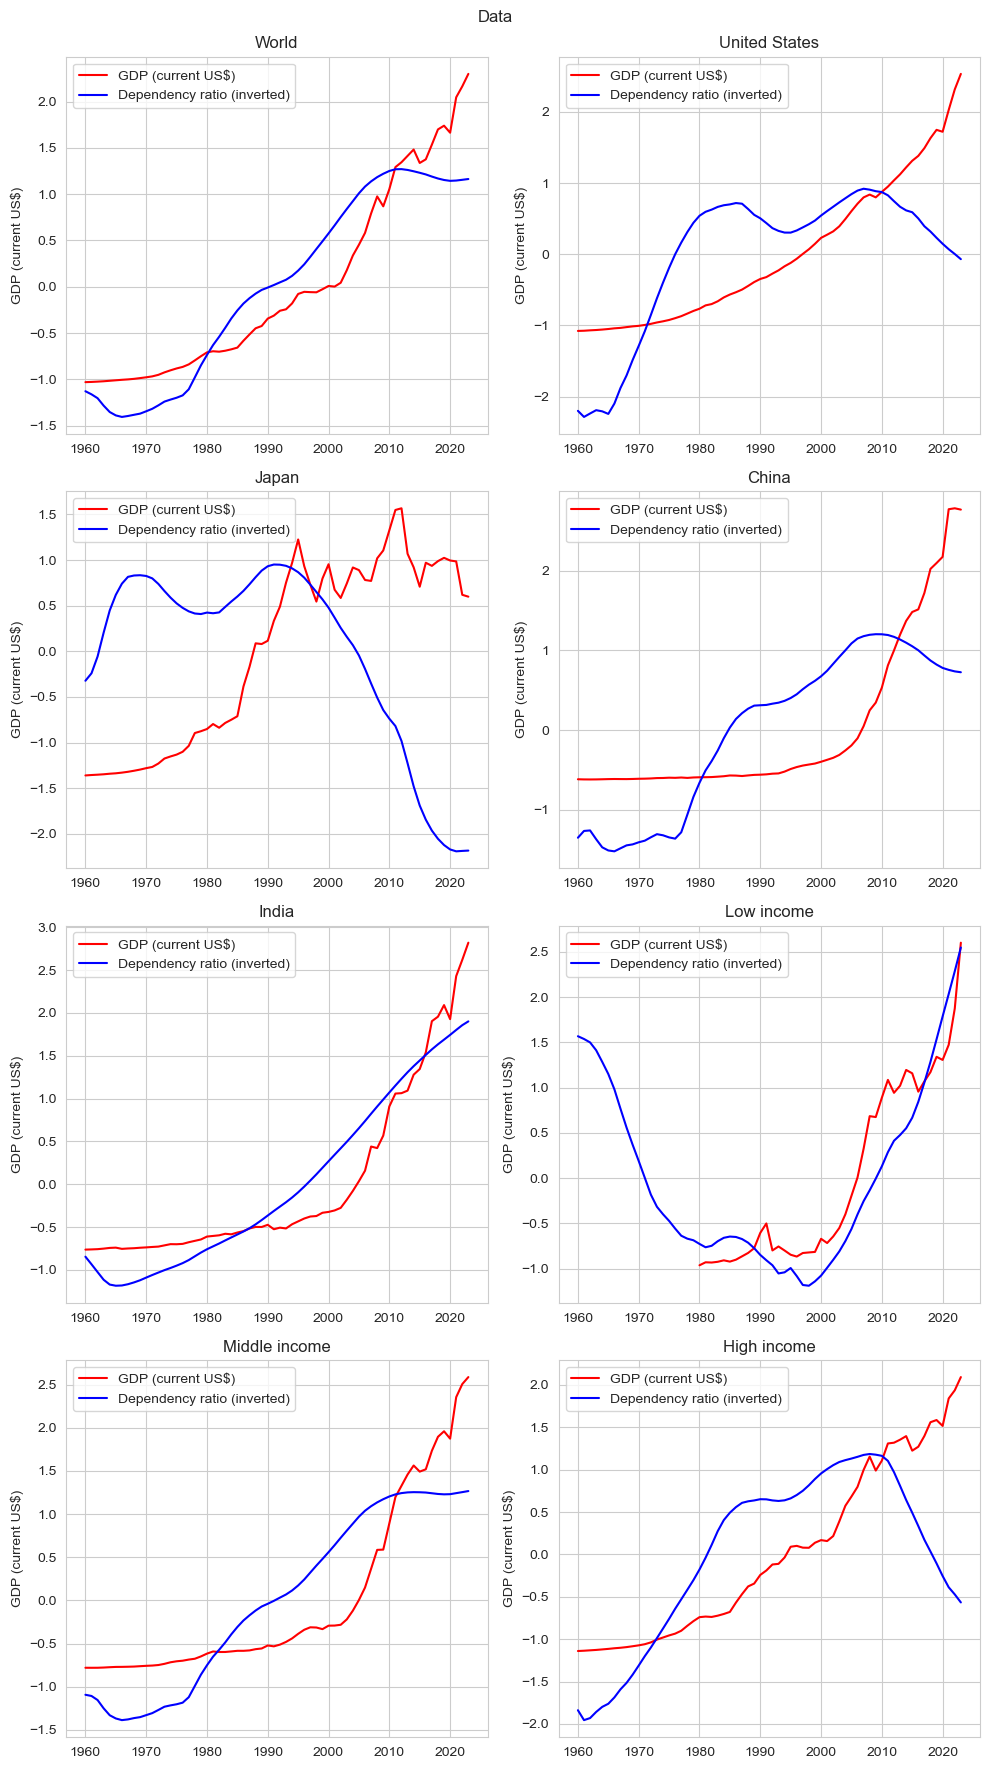

In [93]:
plot_all(plot_dependency_gdp)